# Assignment 1

In [1]:
# imports section

import csv
import json
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from bs4 import BeautifulSoup
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OrdinalEncoder, RobustScaler, StandardScaler

RESOURCES_DIR = Path('resources')
FIGURES_DIR = Path('figures') / 'assignment-1'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

REQUEST_TIMEOUT = 15  # seconds
HEADERS = {'User-Agent': 'ida-labs/1.0 (educational project)'}
RANDOM_STATE = 42

sns.set_theme(style='whitegrid')

## Extract webpage data given the url

Create a Python script that performs basic web scraping on a page to extract all the information into text and returns it as a string. String should not contain tags.

In [2]:
def parse_web_page(url):
    """
    Fetch the content of the given web page.

    Args:
        url (str): The URL of the web page to fetch.

    Returns:
        str: The content of the page as a string.

    Raises:
        HTTPError: If the HTTP request returned an unsuccessful status code.
    """
    response = requests.get(url, headers=HEADERS, timeout=REQUEST_TIMEOUT)
    response.raise_for_status()

    # Pass raw bytes so BeautifulSoup detects the encoding from the page itself.
    soup = BeautifulSoup(response.content, 'lxml')
    for element in soup(['script', 'style', 'noscript', 'template', 'svg', 'iframe']):
        element.decompose()

    lines = (line.strip() for line in soup.get_text(separator='\n').splitlines())
    return '\n'.join(line for line in lines if line)

"""
    Replace the following links with links you wish to parse for this assignemnt.
"""
print(parse_web_page('https://fmi.chnu.edu.ua/')[:255])
print(parse_web_page('https://en.wikipedia.org/wiki/Web_scraping')[:255])

Головна - Факультет математики та інформатики
Перейти до основного вмісту
clg-math@chnu.edu.ua
58012, Україна, м. Чернівці, вул. Університетська, 28
Новини
Всі
Загальні
Оголошення
Події
Студенту
Викладачу
Вітання
Діяльність
Наукова
Конференції
Семінари
Ас


Web scraping - Wikipedia
Jump to content
Main menu
Main menu
move to sidebar
hide
Navigation
Main page
Contents
Current events
Random article
About Wikipedia
Contact us
Contribute
Help
Learn to edit
Community portal
Recent changes
Upload file
Special page


## Get data from the API

Create a python script that performs basic request to API endpoint and saves that data to a JSON file result.json.

In [3]:
def parse_api(api_url, output_path='result.json'):
    """
    Fetch the data of the given API endpoint and save it to result.json.

    Args:
        api_url (str): The URL of the API endpoint.
        output_path (str | Path): Where to save the JSON response.

    Returns:
        None.

    Raises:
        HTTPError: If the HTTP request returned an unsuccessful status code.
    """
    response = requests.get(api_url, headers=HEADERS, timeout=REQUEST_TIMEOUT)
    response.raise_for_status()

    with open(output_path, 'w', encoding='utf-8') as f:
        json.dump(response.json(), f, ensure_ascii=False, indent=2)
    print(f'Saved response from {api_url} to {output_path}')

"""
    Replace the following api with api you wish to parse for this assignemnt.
    You can use https://free-apis.github.io/#/ or any other available api endpoint you like.
"""
parse_api('https://api.github.com/')

Saved response from https://api.github.com/ to result.json


## Parse the json file

Parse the `weather.json` file and return weather data for a specific date, that is given as a parameter. Return the data as an array.

In [4]:
def to_date(value):
    """Parse 'YYYY-M-D' or 'YYYY-MM-DD' into a date, so '2024-8-19' matches '2024-08-19'."""
    return datetime.strptime(value.strip(), '%Y-%m-%d').date()


def parse_json(date, file_path=RESOURCES_DIR / 'weather.json'):
    """
    Parse the data from weather.json file and return weather data for a given date.

    Args:
        date (str): The date for which we look up the weather.
        file_path (str | Path): Location of the json file.

    Returns:
        list: a list of weather data for a given date (empty if the date is missing).
    """
    target = to_date(date)
    with open(file_path, encoding='utf-8') as f:
        data = json.load(f)

    for record in data['daily']:
        if to_date(record['date']) == target:
            return list(record.values())
    return []

target_date = '2024-8-19'
print(parse_json(target_date))

['2024-08-19', 30.0, 21.0, 5.0, 10.0, 70, 'Light rain']


## Parse the csv file

Parse the `weather.csv` file and return weather data for a specific date, that is given as a parameter. Return the data as an array.

In [5]:
def parse_csv(date, file_path=RESOURCES_DIR / 'weather.csv'):
    """
    Parse the data from weather.csv file and return weather data for a given date.

    Args:
        date (str): The date for which we look up the weather.
        file_path (str | Path): Location of the csv file.

    Returns:
        list: a list of weather data for a given date (empty if the date is missing).
    """
    target = to_date(date)
    with open(file_path, newline='', encoding='utf-8') as f:
        reader = csv.reader(f)
        next(reader)  # header
        for row in reader:
            if to_date(row[0]) == target:
                return row
    return []

target_date = '1997-5-22'
print(parse_csv(target_date))

['1997-5-22', '25', '18', '10', '11', '8', '6', '88', '54', '34', '1017', '1015', '1012', '10', '10', '10', '11', '3', '', '0.00', '3', '', '277']


## Visualize data

Visualize the weather.csv data using matplotlib. Choose your own approach to data visualization. Save the results (as .png, .webp files etc., your choise) in this repository.

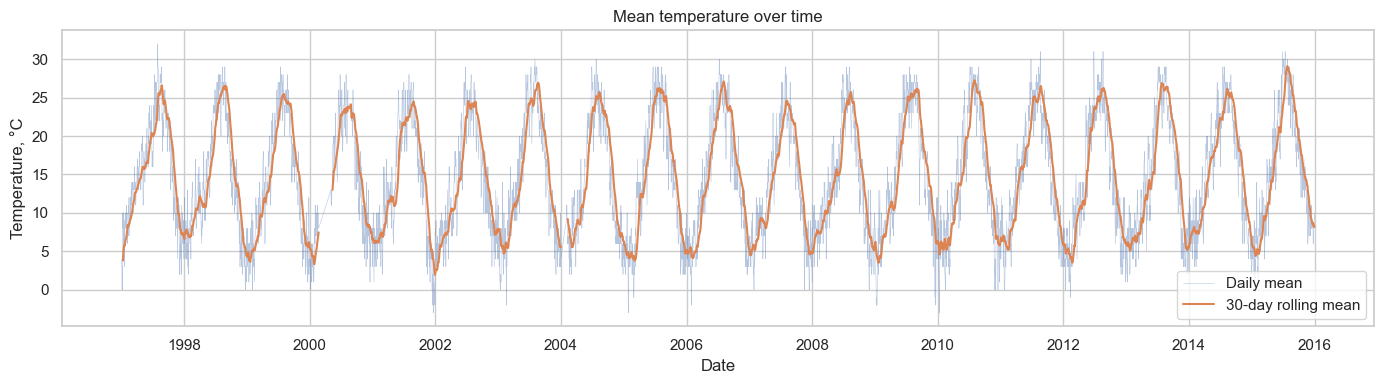

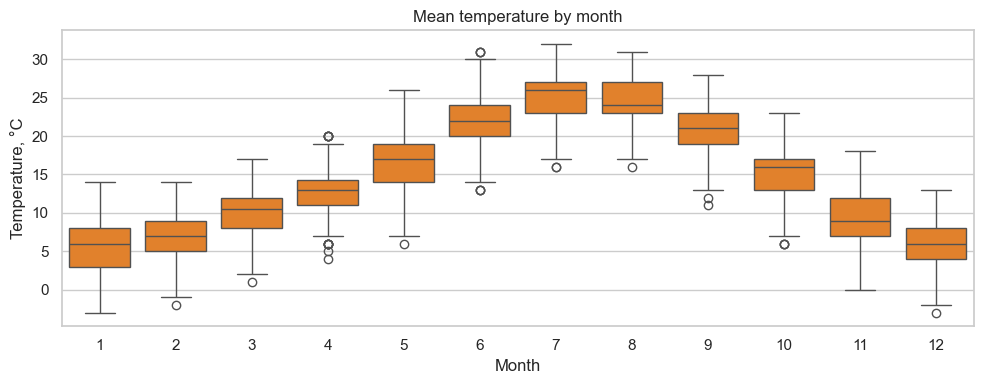

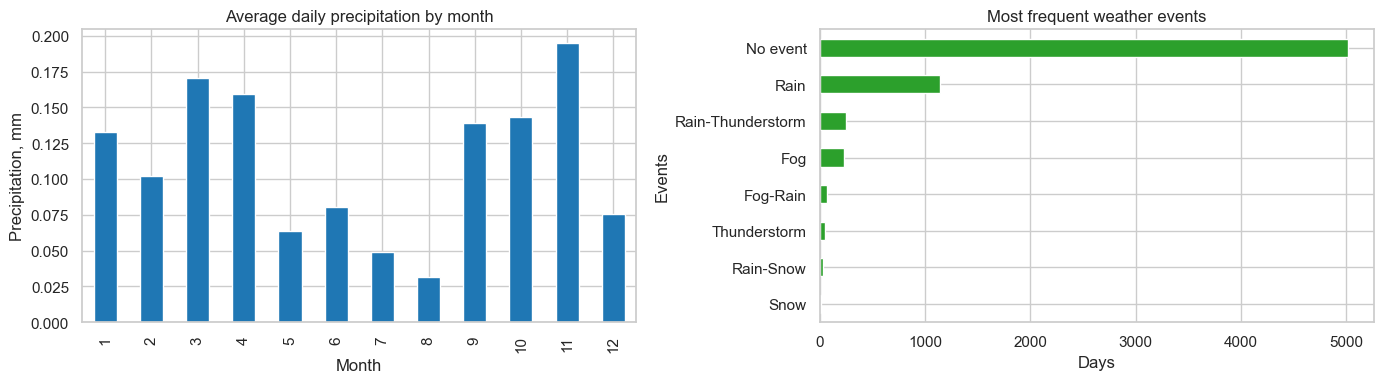

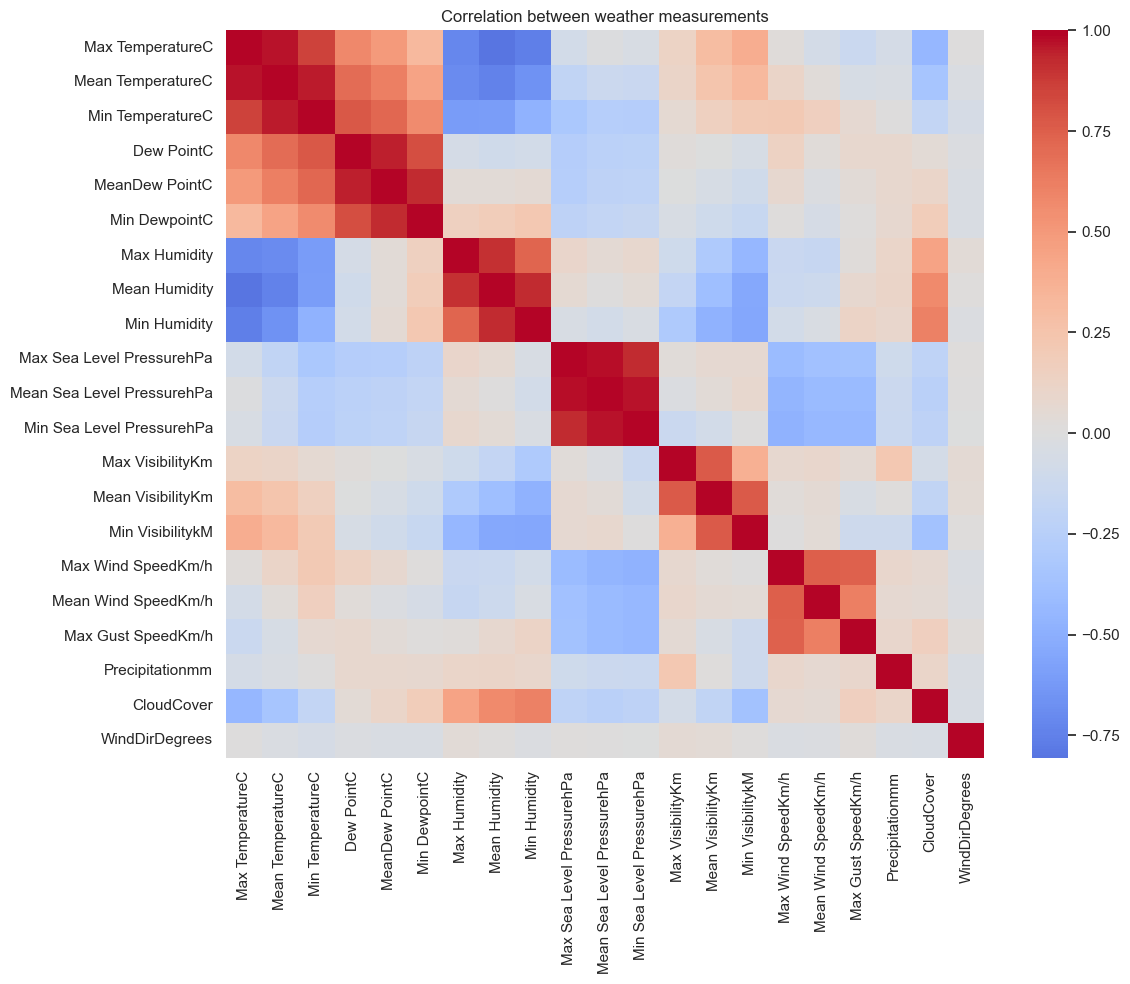

In [ ]:
def load_weather(file_path=RESOURCES_DIR / 'weather.csv'):
    """Load weather.csv into a DataFrame indexed by date, with clean column names."""
    df = pd.read_csv(file_path, skipinitialspace=True)
    df.columns = df.columns.str.strip()
    df['CET'] = pd.to_datetime(df['CET'], format='%Y-%m-%d')
    return df.set_index('CET').sort_index()


def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / name, dpi=120, bbox_inches='tight')
    plt.show()


def visualize_data():
    """
    Parse the data from weather.csv file and visualize it using Matplotlib. Use more then one visualization.
    Save the results in the repository.

    Args:
        None: None.

    Returns:
        None: None.
    """
    df = load_weather()

    # 1. Temperature over time: daily values with a 30-day rolling mean.
    fig, ax = plt.subplots(figsize=(14, 4))
    ax.plot(df.index, df['Mean TemperatureC'], lw=0.4, alpha=0.4, label='Daily mean')
    ax.plot(df.index, df['Mean TemperatureC'].rolling('30D', min_periods=10).mean(), lw=1.5, label='30-day rolling mean')
    ax.set(title='Mean temperature over time', xlabel='Date', ylabel='Temperature, °C')
    ax.legend()
    save_figure(fig, 'temperature_over_time.png')

    # 2. Seasonality: temperature distribution by month.
    monthly = df.assign(Month=df.index.month)
    fig, ax = plt.subplots(figsize=(10, 4))
    sns.boxplot(data=monthly, x='Month', y='Mean TemperatureC', color='tab:orange', ax=ax)
    ax.set(title='Mean temperature by month', ylabel='Temperature, °C')
    save_figure(fig, 'temperature_by_month.png')

    # 3. Precipitation and weather events.
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
    monthly.groupby('Month')['Precipitationmm'].mean().plot.bar(ax=ax1, color='tab:blue')
    ax1.set(title='Average daily precipitation by month', ylabel='Precipitation, mm')
    df['Events'].fillna('No event').value_counts().head(8).plot.barh(ax=ax2, color='tab:green')
    ax2.set(title='Most frequent weather events', xlabel='Days')
    ax2.invert_yaxis()
    save_figure(fig, 'precipitation_and_events.png')

    # 4. Correlation between numeric measurements.
    fig, ax = plt.subplots(figsize=(12, 10))
    sns.heatmap(df.select_dtypes('number').corr(), cmap='coolwarm', center=0, ax=ax)
    ax.set_title('Correlation between weather measurements')
    save_figure(fig, 'correlation_heatmap.png')

visualize_data()

## Data imputation and normalization.

Download kaggle dataset with incomplete/missing data, and try data imputation techniques (mean, median, mode, knn) on that data. Normalize the data with best option for each dataset (minmax, z-score, robust). Visualize the data (choose your own approach to data visualization).

Dataset options:
- Different Types of Missing Data (by Suryaprabha19) https://www.kaggle.com/datasets/suryaprabha19/different-types-of-missing-data
- Retail Product Dataset with Missing Values (by Himel Sarder) https://www.kaggle.com/datasets/himelsarder/retail-product-dataset-with-missing-values
- Data Cleaning - Feature Imputation (by 
Mr.Machine) https://www.kaggle.com/datasets/ilayaraja07/data-cleaning-feature-imputation
- BI intro to data cleaning eda and machine learning (by Walekhwa Tambiti Leo Philip) https://www.kaggle.com/datasets/walekhwatlphilip/intro-to-data-cleaning-eda-and-machine-learning

C:\Users\CoreUltra\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



===== Students_Performance_knn =====


method   knn   mean  median   mode
column                            
lunch   0.68  0.691   0.691  0.691
Imputation method: mode
Outlier share: 0.63%, max |skew|: 0.29
Scaler: StandardScaler


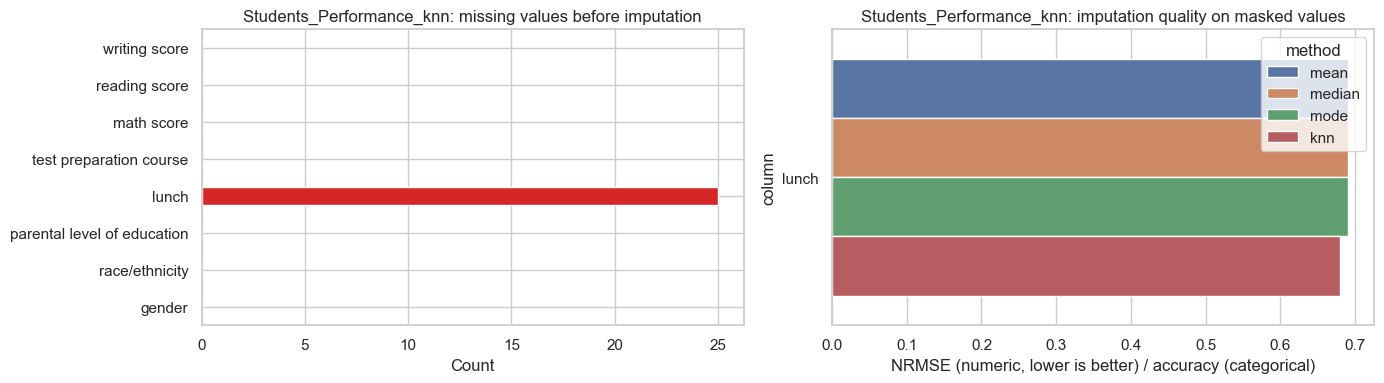

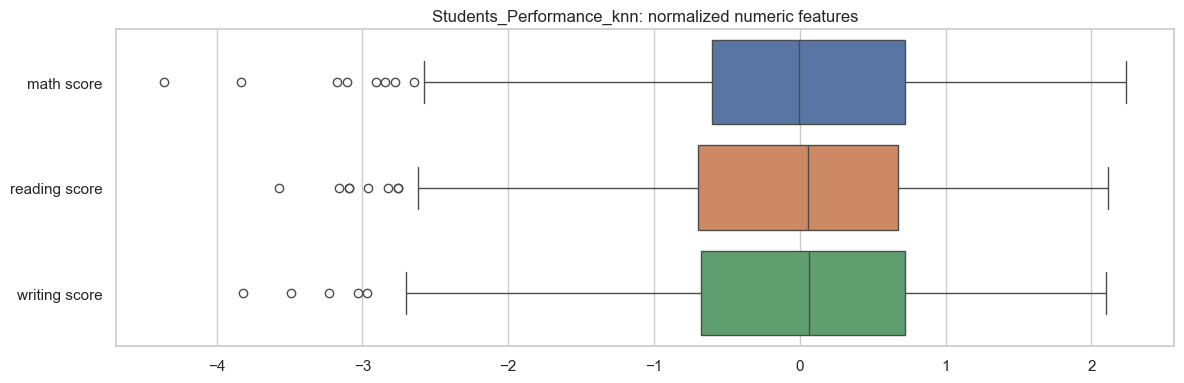

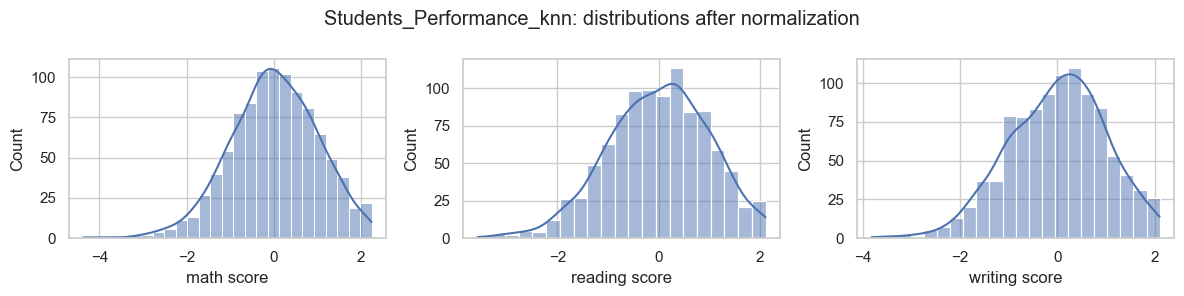

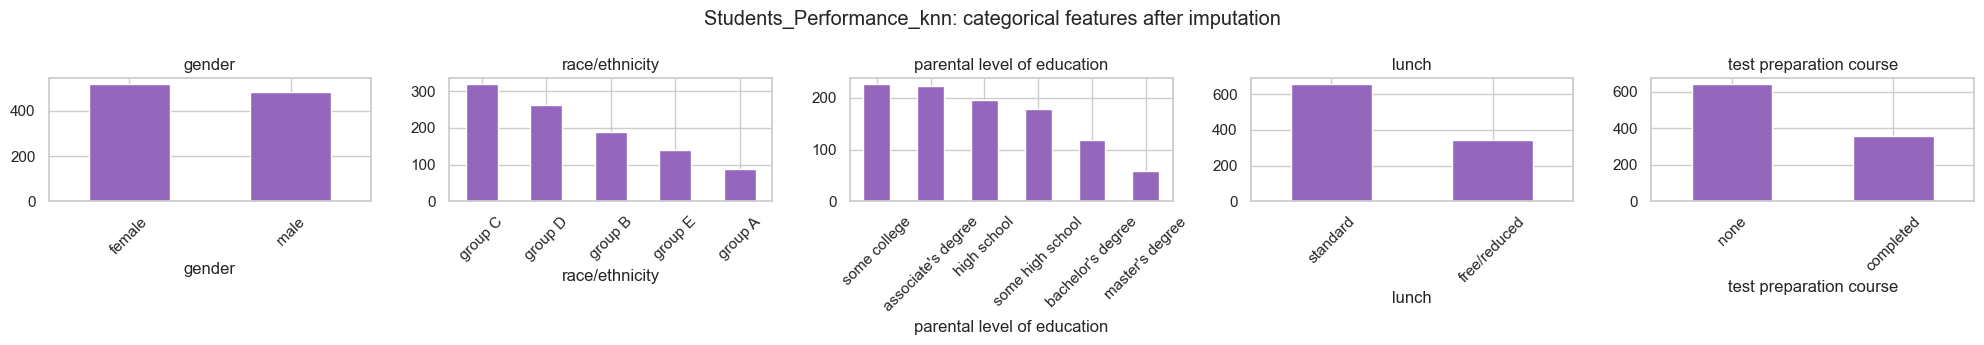


===== Students_Performance_mv =====


method                         knn   mean  median   mode
column                                                  
lunch                        0.663  0.694   0.694  0.694
parental level of education  0.113  0.175   0.175  0.175
race/ethnicity               0.184  0.276   0.276  0.276
test preparation course      0.636  0.646   0.646  0.646
Imputation method: mode
Outlier share: 0.63%, max |skew|: 0.29
Scaler: StandardScaler


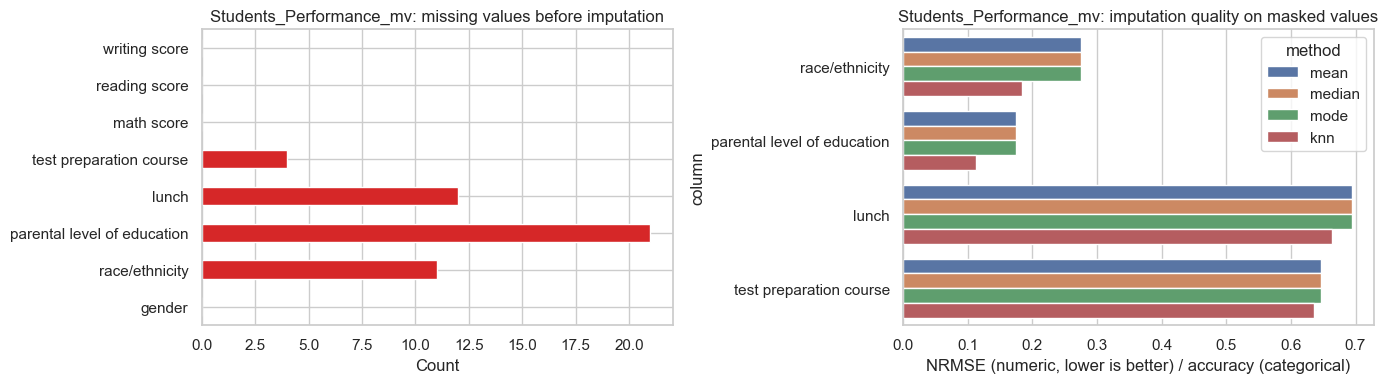

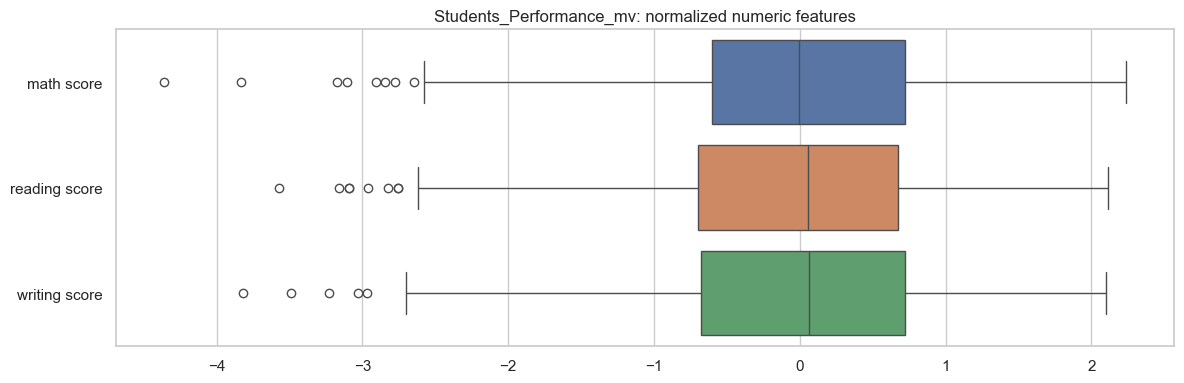

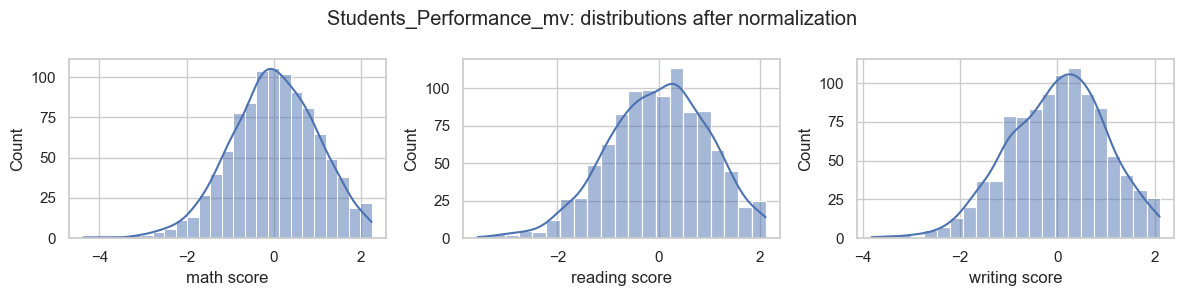

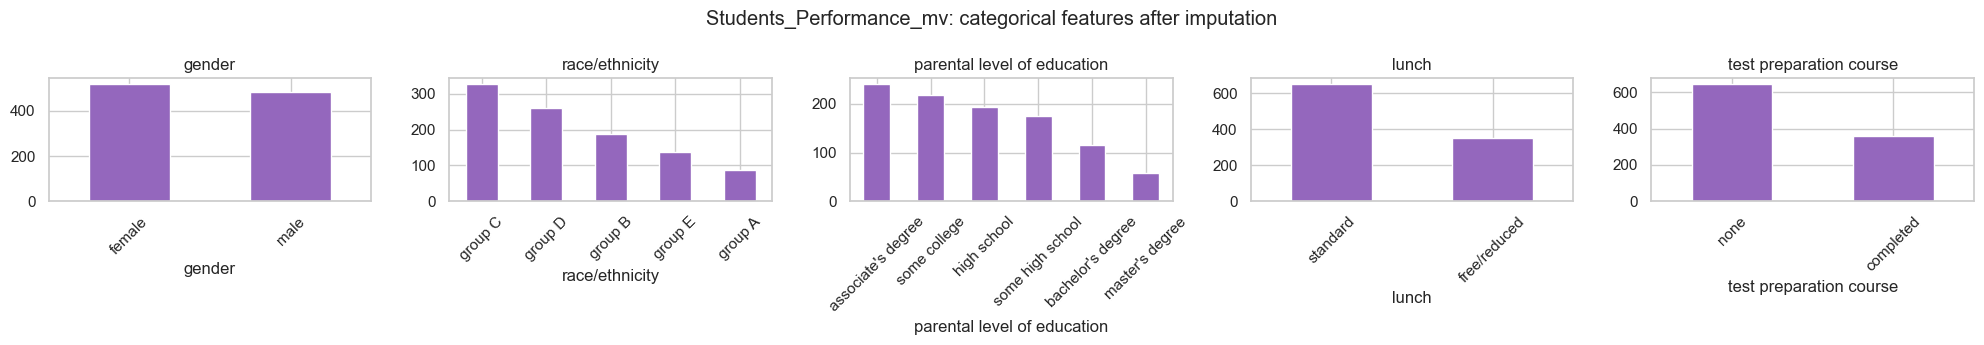


===== Wine_Quality =====


method              knn   mean  median   mode
column                                       
chlorides         0.659  1.142   1.171  1.193
citric acid       0.734  0.996   0.999  1.006
fixed acidity     0.543  1.014   1.022  1.054
pH                0.683  0.965   0.966  1.027
residual sugar    0.609  1.146   1.283  1.392
sulphates         0.657  0.882   0.889  0.901
volatile acidity  0.636  0.995   1.038  1.057
Imputation method: knn
Outlier share: 2.78%, max |skew|: 5.40
Scaler: RobustScaler


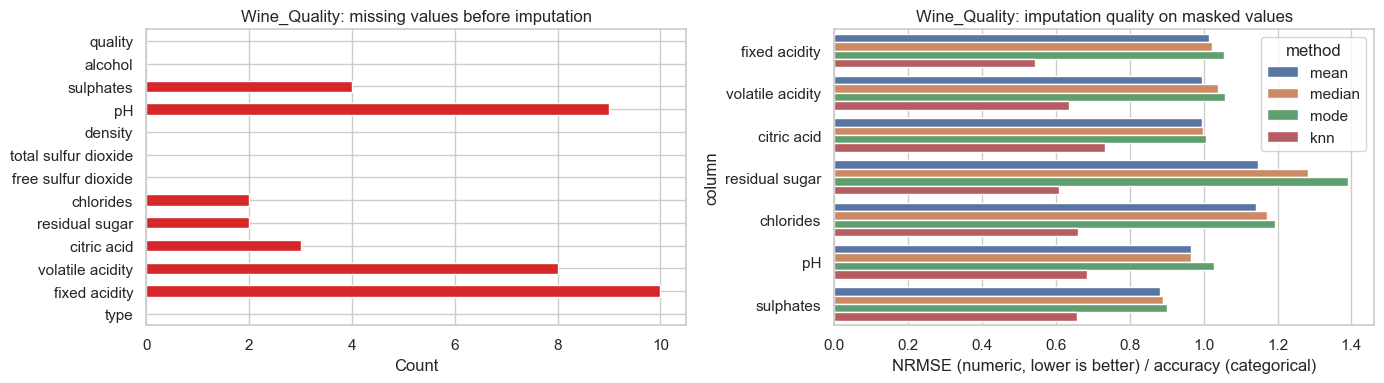

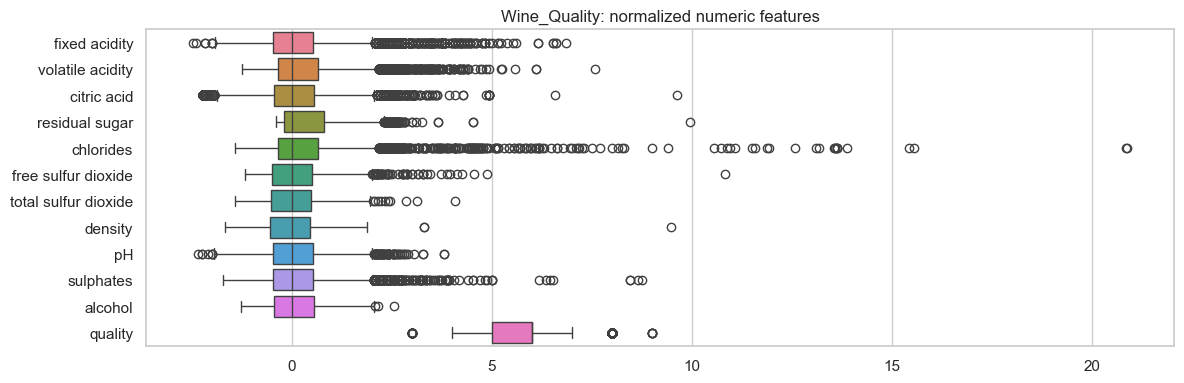

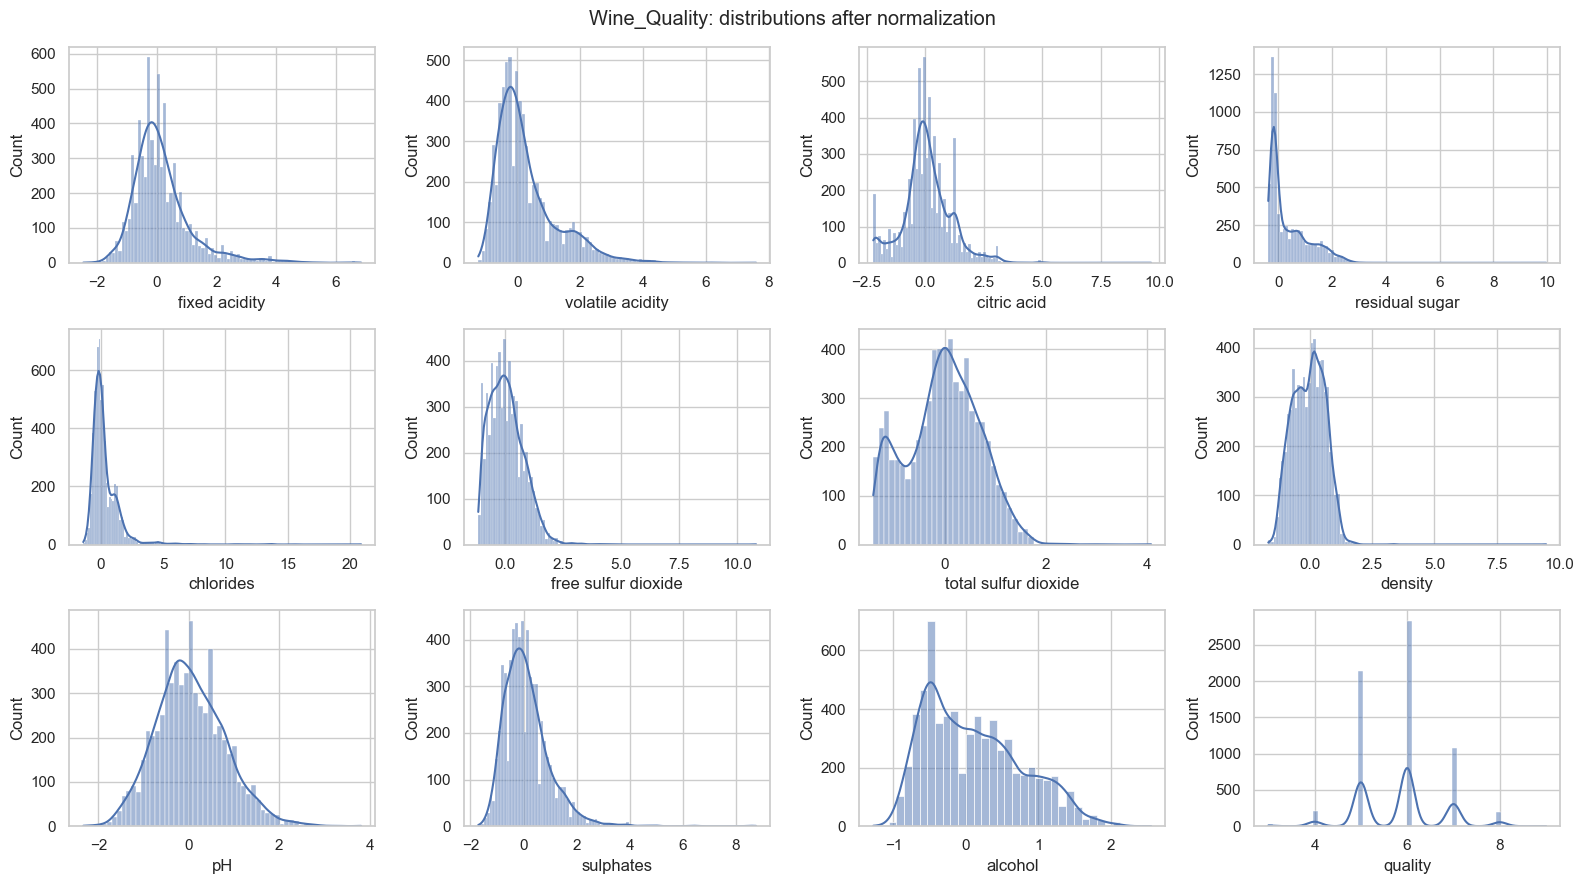

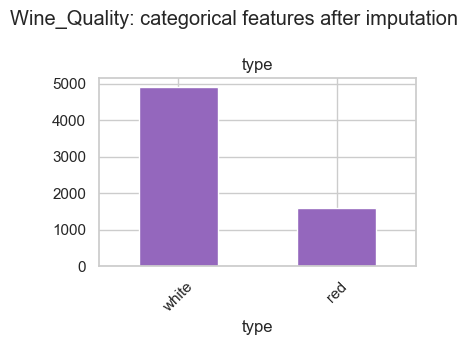

In [7]:
# pip install "kagglehub[pandas-datasets]"

import kagglehub
from kagglehub import KaggleDatasetAdapter

IMPUTATION_METHODS = ('mean', 'median', 'mode', 'knn')


def load_dataset(url, csv_file):
    """
    Load the dataset from Kaggle using kagglehub.

    Args:
        url (str): The URL of the Kaggle dataset.
        csv_file (str): The name of the CSV file to load from the dataset.
    Returns:
        pd.DataFrame: The loaded dataset as a pandas DataFrame.
    """
    df = kagglehub.dataset_load(
            KaggleDatasetAdapter.PANDAS,
            url,
            csv_file
        )
    return df


def split_columns(df):
    numeric = df.select_dtypes('number').columns.tolist()
    categorical = [c for c in df.columns if c not in numeric]
    return numeric, categorical


def impute_with(df, method):
    """
    Impute missing values with a single method.

    'mean' and 'median' apply to numeric columns only, so categorical columns always fall
    back to the mode. 'knn' encodes categories, scales all columns (distances must not be
    dominated by large-valued features) and imputes from the 5 nearest rows.
    """
    df = df.copy()
    numeric, categorical = split_columns(df)
    df[categorical] = df[categorical].astype(object)

    if method in ('mean', 'median', 'mode'):
        numeric_strategy = 'most_frequent' if method == 'mode' else method
        if numeric:
            df[numeric] = SimpleImputer(strategy=numeric_strategy).fit_transform(df[numeric])
        if categorical:
            df[categorical] = SimpleImputer(strategy='most_frequent').fit_transform(df[categorical])
        return df

    if method == 'knn':
        encoder = OrdinalEncoder()  # keeps NaN as NaN
        encoded = df.copy()
        if categorical:
            encoded[categorical] = encoder.fit_transform(df[categorical])
        scaler = StandardScaler()  # ignores NaN while fitting
        imputed = scaler.inverse_transform(KNNImputer(n_neighbors=5).fit_transform(scaler.fit_transform(encoded)))
        imputed = pd.DataFrame(imputed, columns=df.columns, index=df.index)
        if numeric:
            df[numeric] = imputed[numeric]
        if categorical:
            codes = imputed[categorical].round()
            for i, column in enumerate(categorical):
                codes[column] = codes[column].clip(0, len(encoder.categories_[i]) - 1)
            df[categorical] = encoder.inverse_transform(codes)
        return df

    raise ValueError(f'Unknown imputation method: {method}')


def evaluate_imputers(df, mask_fraction=0.1, random_state=RANDOM_STATE):
    """
    Score each imputation method on values we know: hide a fraction of observed cells in
    the columns that have missing data, impute them back and compare with the truth.
    Numeric columns are scored with RMSE / std (lower is better), categorical with accuracy.
    """
    rng = np.random.default_rng(random_state)
    numeric, _ = split_columns(df)
    columns = df.columns[df.isna().any()].tolist()

    masked = df.copy()
    hidden = {}
    for column in columns:
        observed = df.index[df[column].notna()]
        hidden[column] = rng.choice(observed, size=max(1, int(len(observed) * mask_fraction)), replace=False)
        masked.loc[hidden[column], column] = np.nan

    rows = []
    for method in IMPUTATION_METHODS:
        imputed = impute_with(masked, method)
        for column in columns:
            truth, guess = df.loc[hidden[column], column], imputed.loc[hidden[column], column]
            if column in numeric:
                score = np.sqrt(np.mean((truth - guess.astype(float)) ** 2)) / df[column].std()
                metric = 'NRMSE'
            else:
                score = (truth == guess).mean()
                metric = 'accuracy'
            rows.append({'method': method, 'column': column, 'metric': metric, 'score': score})
    return pd.DataFrame(rows)


def best_imputation_method(scores):
    """Rank methods by NRMSE (numeric) and by error rate (categorical): lower is better."""
    error = np.where(scores['metric'] == 'accuracy', 1 - scores['score'], scores['score'])
    # On ties (e.g. only categorical gaps, where mean/median fall back to the mode) prefer the simplest method.
    preference = ['mode', 'median', 'mean', 'knn']
    return scores.assign(error=error).groupby('method')['error'].mean().reindex(preference).idxmin()


def impute_data(df, method=None):
    """
    Parse the data from file and impute missing values using your preferred method.

    Args:
        df (pd.DataFrame): The dataset as a pandas DataFrame.
        method (str | None): One of IMPUTATION_METHODS; None picks the best one on masked data.

    Returns:
        pd.DataFrame: The dataset with imputed values.
    """
    if not df.isna().any().any():
        return df.copy()
    if method is None:
        scores = evaluate_imputers(df)
        print(scores.pivot_table(index='column', columns='method', values='score').round(3))
        method = best_imputation_method(scores)
    print(f'Imputation method: {method}')
    return impute_with(df, method)


def choose_scaler(df):
    """
    Pick the scaler from the shape of numeric data:
    - RobustScaler if more than 1% of values are IQR outliers (median/IQR are not pulled by them);
    - StandardScaler (z-score) if all columns are roughly symmetric;
    - MinMaxScaler otherwise (skewed but bounded data).
    """
    q1, q3 = df.quantile(0.25), df.quantile(0.75)
    iqr = q3 - q1
    outlier_share = ((df < q1 - 1.5 * iqr) | (df > q3 + 1.5 * iqr)).to_numpy().mean()
    max_skew = df.skew().abs().max()
    print(f'Outlier share: {outlier_share:.2%}, max |skew|: {max_skew:.2f}')
    if outlier_share > 0.01:
        return RobustScaler()
    if max_skew < 1:
        return StandardScaler()
    return MinMaxScaler()


def normalize_data(df, exclude=()):
    """
    Normalize the data using your preferred method.

    Args:
        df (pd.DataFrame): The dataset as a pandas DataFrame.
        exclude (iterable): Numeric columns to keep as is (e.g. the target).

    Returns:
        pd.DataFrame: The dataset with normalized values.
    """
    df = df.copy()
    numeric, _ = split_columns(df)
    columns = [c for c in numeric if c not in exclude]
    scaler = choose_scaler(df[columns])
    print(f'Scaler: {type(scaler).__name__}')
    df[columns] = scaler.fit_transform(df[columns])
    return df


def visualize_data(df, raw_df=None, name='dataset'):
    """
    Visualize the data using Matplotlib. Use more then one visualization.
    Save the results in the repository.

    Args:
        df (pd.DataFrame): The dataset as a pandas DataFrame.
        raw_df (pd.DataFrame | None): The dataset before imputation, to show missing values.
        name (str): Dataset name used in titles and file names.

    Returns:
        None: None.
    """
    numeric, categorical = split_columns(df)

    if raw_df is not None:
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
        raw_df.isna().sum().plot.barh(ax=ax1, color='tab:red')
        ax1.set(title=f'{name}: missing values before imputation', xlabel='Count')
        scores = evaluate_imputers(raw_df)
        sns.barplot(data=scores, x='score', y='column', hue='method', ax=ax2)
        ax2.set(title=f'{name}: imputation quality on masked values', xlabel='NRMSE (numeric, lower is better) / accuracy (categorical)')
        save_figure(fig, f'{name}_imputation.png')

    fig, ax = plt.subplots(figsize=(12, 4))
    sns.boxplot(data=df[numeric], orient='h', ax=ax)
    ax.set(title=f'{name}: normalized numeric features')
    save_figure(fig, f'{name}_normalized_boxplot.png')

    n = len(numeric)
    cols = min(n, 4)
    fig, axes = plt.subplots((n + cols - 1) // cols, cols, figsize=(4 * cols, 3 * ((n + cols - 1) // cols)), squeeze=False)
    for ax, column in zip(axes.flat, numeric):
        sns.histplot(df[column], kde=True, ax=ax)
    for ax in axes.flat[n:]:
        ax.set_visible(False)
    fig.suptitle(f'{name}: distributions after normalization')
    save_figure(fig, f'{name}_distributions.png')

    if categorical:
        fig, axes = plt.subplots(1, len(categorical), figsize=(4 * len(categorical), 3.5), squeeze=False)
        for ax, column in zip(axes.flat, categorical):
            df[column].value_counts().plot.bar(ax=ax, color='tab:purple')
            ax.set_title(column)
            ax.tick_params(axis='x', rotation=45)
        fig.suptitle(f'{name}: categorical features after imputation')
        save_figure(fig, f'{name}_categorical.png')


DATASET = 'ilayaraja07/data-cleaning-feature-imputation'
datasets = {
    # file name: numeric columns not to normalize (targets)
    'Students_Performance_knn.csv': (),
    'Students_Performance_mv.csv': (),
    'Wine_Quality.csv': ('quality',),
}

for csv_file, exclude in datasets.items():
    name = Path(csv_file).stem
    print(f'\n===== {name} =====')
    raw_df = load_dataset(DATASET, csv_file)
    df = impute_data(raw_df)
    df = normalize_data(df, exclude=exclude)
    visualize_data(df, raw_df=raw_df, name=name)